## Results 2026-11-13 - tables and figures

Tables and figures for `docs/results/2026-11-13-results.md`: the recovery schedule screens (Recovery-1 at 100M,
Recovery-2 at 1B) and Heterogeneous-2 Step 1. Every value is read from the result artifacts under
`data/results/workflows/model/`; nothing is copied from a document, except B 20% INT4's byte saving, which comes from
the [2026-11-01 notebook](results-2026-11-01.ipynb). The notebook is load-only: it loads no model and no dataset.
Recovery-1's `summary-001` was written on PERUN after its results were copied home, so its rule is recomputed here
from the run artifacts.

setup

In [1]:
import json
import statistics
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

In [2]:
def find_project_root(start):
    start = start.resolve()
    for candidate in (start, *start.parents):
        if (candidate / 'src' / 'mlp_replacement').is_dir():
            return candidate
    raise RuntimeError('Could not locate the repository root')


PROJECT_ROOT = find_project_root(Path.cwd())
RESULTS_ROOT = PROJECT_ROOT / 'data' / 'results' / 'workflows' / 'model'
FIGURE_DIRECTORY = PROJECT_ROOT / 'docs' / 'images' / 'results' / '2026-11-13'
SAVE_FIGURES = True
FIGURE_DPI = 150

FIGURE_DIRECTORY.mkdir(parents=True, exist_ok=True)
pd.set_option('display.width', 220)
pd.set_option('display.max_columns', 20)

artifacts and constants

In [3]:
FAMILIES = {'dense-int3': 'Dense INT3 QAT', 'b-0.2-int4': 'B 20% INT4', 'swiglu-0.2': 'SwiGLU 20%'}
BAR = 0.035  # the 3.5% bar of every rule below (decision log, 2026-11-07 and 2026-11-08)
# Recovery-1: lowest trunk value at 75/80/90/100M; Recovery-2: median at 750/800/900/1000M.
RECOVERY_1_REFERENCE = [75_000_000, 80_000_000, 90_000_000, 100_000_000]
RECOVERY_2_REFERENCE = [750_000_000, 800_000_000, 900_000_000, 1_000_000_000]
HETEROGENEOUS_TARGETS = {'0.2': '20%', '0.5': '50%', '0.8': '80%'}
DENSE_RUN = 'quantization-1/dense-001'
INT3_QAT_1B_RUN = 'quantization-2/qat-int3-1b-002'
B_20_INT4_BYTE_SAVING = 0.509  # Results-2 notebook (calculated INT4 bytes of the 20% SwiGLU widths)


def load_result(relative):
    return json.loads((RESULTS_ROOT / relative / 'result.json').read_text(encoding='utf-8'))


def last_request(row):
    requested = row['requested_tokens']
    return int(requested[-1] if isinstance(requested, list) else requested)


def workflow_hours(result):
    elapsed = datetime.fromisoformat(result['updated_at_utc']) - datetime.fromisoformat(result['created_at_utc'])
    return elapsed.total_seconds() / 3600


recovery_1 = {family: load_result(f'recovery-1/{family}-run-001') for family in FAMILIES}
recovery_2 = {family: load_result(f'recovery-2/{family}-run-001') for family in FAMILIES}
recovery_2_summary = load_result('recovery-2/summary-001')['results']['families']
heterogeneous_summary = load_result('heterogeneous-2/summary-001')['results']
HETEROGENEOUS_RUNS = ['swiglu-0.8-control', 'forced-0.2', 'forced-0.5', 'forced-0.8', 'forced-0.8-lr1e-4', 'swiglu-0.8-lr1e-4']
heterogeneous = {name: load_result(f'heterogeneous-2/{name}-run-001') for name in HETEROGENEOUS_RUNS}
assert all(result['status'] == 'completed' for result in [*recovery_1.values(), *recovery_2.values(), *heterogeneous.values()])

recovery: the winner rule at 100M (Recovery-1) and 1B (Recovery-2)

In [4]:
def apply_rule(result, reference_rows, reduce):
    """Reference from the trunk; a decay qualifies below reference x (1 - bar); the shorter decay within the bar of the best wins."""
    trunk = result['results']['trunk']['history']
    values = {last_request(row): row['selection_kl'] for row in trunk if last_request(row) in reference_rows}
    reference = reduce([values[tokens] for tokens in reference_rows])
    decays = {}
    for percent, branch in sorted(result['results']['branches'].items(), key=lambda item: int(item[0])):
        final = branch['history'][-1]['selection_kl']
        decays[int(percent)] = {'value': final, 'gain': 1 - final / reference, 'qualifies': final < reference * (1 - BAR)}
    qualifying = {percent: row['value'] for percent, row in decays.items() if row['qualifies']}
    winner = None
    if qualifying:
        best = min(qualifying.values())
        winner = min(percent for percent, value in qualifying.items() if value <= best * (1 + BAR))
    return reference, decays, winner


def decision_label(winner):
    return 'constant' if winner is None else f'{winner}% decay'


rows = []
for family, label in FAMILIES.items():
    reference_1, decays_1, winner_1 = apply_rule(recovery_1[family], RECOVERY_1_REFERENCE, min)
    reference_2, decays_2, winner_2 = apply_rule(recovery_2[family], RECOVERY_2_REFERENCE, statistics.median)
    assert winner_2 == recovery_2_summary[family]['decay_percent'], family  # matches summary-001
    trunk_end = recovery_2[family]['results']['trunk']['history'][-1]['selection_kl']
    rows.append({
        'family': label,
        '100M gains 10/20/50%': ' / '.join(f'{100 * decays_1[p]["gain"]:+.1f}%' for p in (10, 20, 50)),
        '100M decision': decision_label(winner_1),
        '1B reference (median)': f'{reference_2:.4f}',
        '1B gains 20/50%': ' / '.join(f'{100 * decays_2[p]["gain"]:+.1f}%' for p in (20, 50)),
        '1B decision': decision_label(winner_2),
        'winner vs trunk 1B row': f'{100 * (1 - decays_2[winner_2]["value"] / trunk_end):+.1f}%' if winner_2 else '-',
    })
recovery_table = pd.DataFrame(rows)
recovery_table

,family,100M gains 10/20/50%,100M decision,1B reference (median),1B gains 20/50%,1B decision,winner vs trunk 1B row
0,Dense INT3 QAT,+2.4% / +5.8% / +7.6%,20% decay,0.0835,+27.2% / +35.1%,50% decay,+36.1%
1,B 20% INT4,+0.6% / +0.3% / -2.5%,constant,0.0824,+5.6% / +3.9%,20% decay,+3.6%
2,SwiGLU 20%,+0.0% / -0.4% / -1.9%,constant,0.0629,+3.7% / +1.3%,20% decay,+1.3%


plot style

In [5]:
SURFACE = '#fcfcfb'
TEXT = '#0b0b0b'
TEXT_SECONDARY = '#52514e'
GRID = '#e1e0d9'
BAND = '#efeeeb'
# Categorical hues of the 2026-11-01 report, all pairs validated on this surface (dataviz validator).
BLUE = '#2a78d6'
ORANGE = '#eb6834'
GREEN = '#1baf7a'
REFERENCE_LINE = TEXT_SECONDARY  # the constant trunk is a neutral reference, not a series hue


def style_axes(ax):
    ax.set_facecolor(SURFACE)
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
    for side in ('left', 'bottom'):
        ax.spines[side].set_color(GRID)
    ax.grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=TEXT_SECONDARY, labelsize=9)

recovery, figure: the constant trunk and both decays at 1B

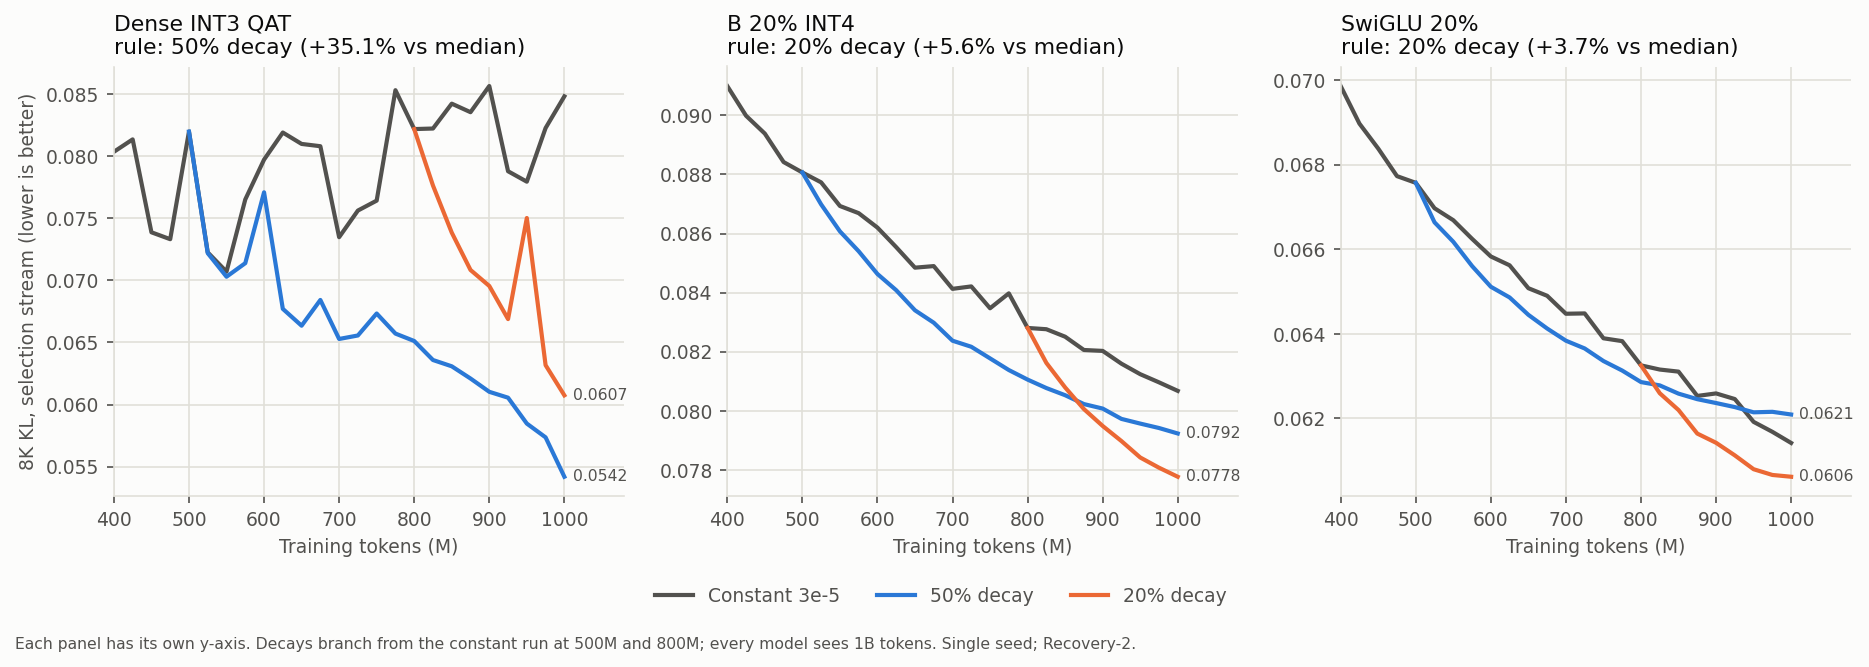

In [6]:
def branch_curve(result, percent):
    """The decay's rows, starting from the trunk row it branched from."""
    branch = result['results']['branches'][str(percent)]
    trunk = {row['actual_tokens']: row['selection_kl'] for row in result['results']['trunk']['history']}
    start = branch['decay_start_tokens']
    tokens = [start] + [row['actual_tokens'] for row in branch['history']]
    values = [trunk[start]] + [row['selection_kl'] for row in branch['history']]
    return tokens, values


X_START = 400_000_000
fig, axes = plt.subplots(1, 3, figsize=(12.6, 4.4), dpi=FIGURE_DPI)
fig.patch.set_facecolor(SURFACE)
for ax, (family, label) in zip(axes, FAMILIES.items()):
    style_axes(ax)
    result = recovery_2[family]
    trunk = [row for row in result['results']['trunk']['history'] if row['actual_tokens'] >= X_START]
    ax.plot([row['actual_tokens'] / 1e6 for row in trunk], [row['selection_kl'] for row in trunk],
            color=REFERENCE_LINE, linewidth=2, label='Constant 3e-5', zorder=2)
    for percent, color in ((50, BLUE), (20, ORANGE)):
        tokens, values = branch_curve(result, percent)
        ax.plot([value / 1e6 for value in tokens], values, color=color, linewidth=2, label=f'{percent}% decay', zorder=3)
        ax.annotate(f'{values[-1]:.4f}', (1000, values[-1]), xytext=(4, 0), textcoords='offset points',
                    fontsize=7.5, color=TEXT_SECONDARY, va='center')
    winner = recovery_2_summary[family]['decay_percent']
    gain = recovery_2_summary[family]['selection']['candidates'][[20, 50].index(winner)]['gain']
    ax.set_title(f'{label}\nrule: {winner}% decay ({100 * gain:+.1f}% vs median)', loc='left', color=TEXT, fontsize=10.5)
    ax.set_xlim(X_START / 1e6, 1080)
    ax.set_xlabel('Training tokens (M)', color=TEXT_SECONDARY, fontsize=9)
axes[0].set_ylabel('8K KL, selection stream (lower is better)', color=TEXT_SECONDARY, fontsize=9)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=3, frameon=False, fontsize=9, labelcolor=TEXT_SECONDARY,
           bbox_to_anchor=(0.5, 0.045))
fig.text(0.01, 0.005, 'Each panel has its own y-axis. Decays branch from the constant run at 500M and 800M; every model sees 1B tokens. '
         'Single seed; Recovery-2.', fontsize=7.5, color=TEXT_SECONDARY)
fig.tight_layout(rect=(0, 0.11, 1, 1))
if SAVE_FIGURES:
    fig.savefig(FIGURE_DIRECTORY / 'recovery-decays-1b.png', facecolor=SURFACE)
plt.show()

recovery: the two ~51% models at 1B, each with its best schedule

In [7]:
dense_bytes = load_result(DENSE_RUN)['results']['footprint']['weight_storage_bytes']
int3_saving = 1 - load_result(INT3_QAT_1B_RUN)['results']['calculated_footprint']['weight_bytes'] / dense_bytes
pair = []
for family, saving in (('dense-int3', int3_saving), ('b-0.2-int4', B_20_INT4_BYTE_SAVING)):
    entry = recovery_2_summary[family]
    winner = entry['decay_percent']
    best = next(row['value'] for row in entry['selection']['candidates'] if row['decay_percent'] == winner)
    pair.append({'model': FAMILIES[family], 'byte saving': f'{100 * saving:.1f}%',
                 'constant, 1B': f'{entry["selection"]["trunk_1b"]:.4f}', 'best schedule': f'{winner}% decay',
                 'best, 1B': f'{best:.4f}'})
pair_table = pd.DataFrame(pair)
lead = 1 - float(pair_table.loc[0, 'best, 1B']) / float(pair_table.loc[1, 'best, 1B'])
print(f'Dense INT3 below B 20% INT4 at the best schedules: {100 * lead:.1f}%')
pair_table

Dense INT3 below B 20% INT4 at the best schedules: 30.3%


,model,byte saving,"constant, 1B",best schedule,"best, 1B"
0,Dense INT3 QAT,51.6%,0.0848,50% decay,0.0542
1,B 20% INT4,50.9%,0.0807,20% decay,0.0778


heterogeneous-2 step 1: the forced-model gap

In [8]:
targets = heterogeneous_summary['targets']
hetero_rows = []
for target, label in HETEROGENEOUS_TARGETS.items():
    gaps = targets[target]['gap_by_tokens']
    decision = targets[target]['decision']
    hetero_rows.append({
        'target': label,
        'token 0': f'{100 * gaps["0"]:+.1f}%', '10M': f'{100 * gaps["10000000"]:+.1f}%',
        '50M': f'{100 * gaps["50000000"]:+.1f}%', '100M': f'{100 * gaps["100000000"]:+.1f}%',
        '8K KL gap': f'{100 * decision["gap_8k"]:+.1f}%', 'band': decision['band'],
        'outcome': 'go to 1B' if decision['go_to_1b'] else 'stop',
    })
control = heterogeneous_summary['control']
print(f'control passed: {control["passed"]}, largest curve difference {100 * control["largest_relative_difference"]:.3f}%')
pd.DataFrame(hetero_rows)

control passed: True, largest curve difference 0.081%


,target,token 0,10M,50M,100M,8K KL gap,band,outcome
0,20%,+20.5%,+18.7%,+18.1%,+16.9%,+15.4%,worse,stop
1,50%,+8.9%,+8.1%,+7.9%,+8.2%,+7.2%,worse,stop
2,80%,+7.6%,+3.1%,+2.4%,+2.1%,+2.3%,level,go to 1B


In [9]:
def monitoring(name):
    rows = heterogeneous[name]['results']['recovery']['validation_history']
    return {row['actual_tokens']: row['recovery_validation_kl'] for row in rows}


recorded_swiglu = {check['tokens']: check['reference'] for check in control['checks'] if 'tokens' in check}
rate_check = targets['0.8']['rate_check']
swiglu_high, forced_high, forced_low = monitoring('swiglu-0.8-lr1e-4'), monitoring('forced-0.8-lr1e-4'), monitoring('forced-0.8')
final = 100_000_000
pd.DataFrame([
    {'model': 'SwiGLU 80%', '3e-5': f'{recorded_swiglu[final]:.4f}', '1e-4': f'{swiglu_high[final]:.4f}',
     'gain at 1e-4': f'{100 * (1 - swiglu_high[final] / recorded_swiglu[final]):.1f}%'},
    {'model': 'Forced 80%', '3e-5': f'{forced_low[final]:.4f}', '1e-4': f'{forced_high[final]:.4f}',
     'gain at 1e-4': f'{100 * (1 - forced_high[final] / forced_low[final]):.1f}%'},
]).assign(note=['recorded SwiGLU-8 run at 3e-5', f'gap at better rates {100 * rate_check["gap_at_better_rates"]:+.1f}%, '
                f'shift {100 * rate_check["shift_toward_new_blocks"]:+.1f} pts'])

,model,3e-5,1e-4,gain at 1e-4,note
0,SwiGLU 80%,0.5244,0.4731,9.8%,recorded SwiGLU-8 run at 3e-5
1,Forced 80%,0.5354,0.4878,8.9%,"gap at better rates +3.1%, shift -1.0 pts"


heterogeneous-2, figure: the gap closes only at 80%

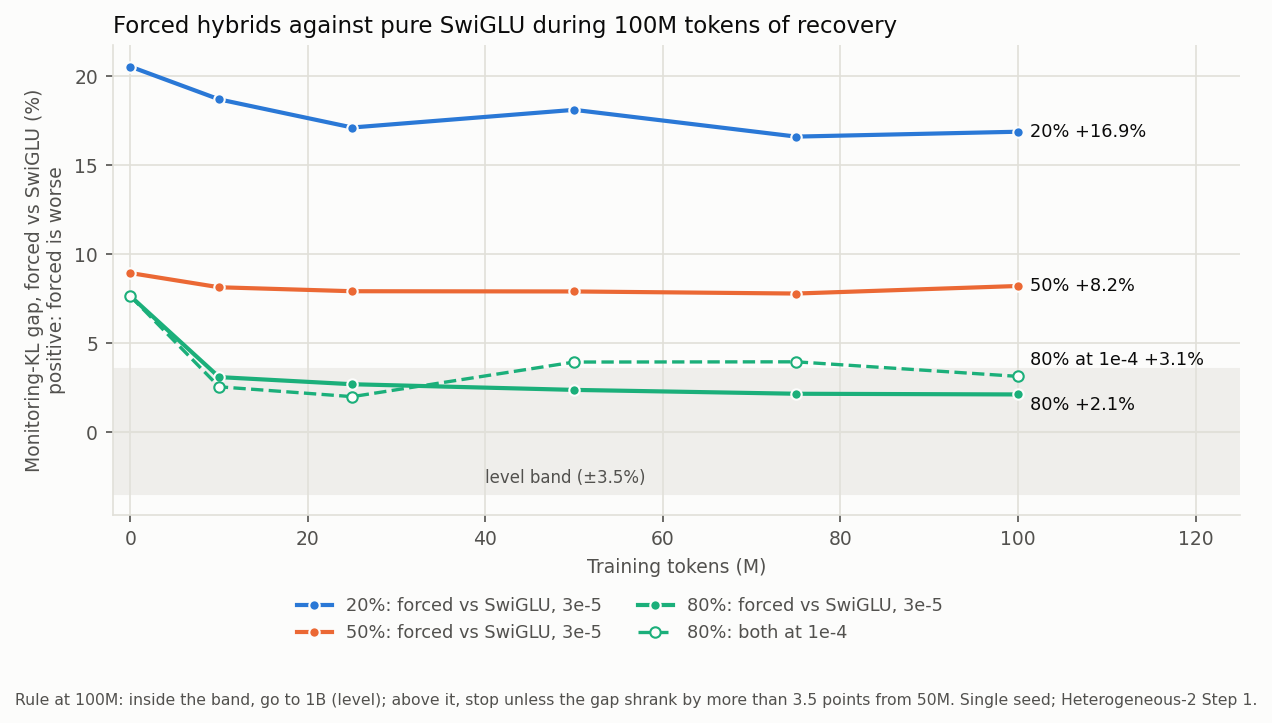

In [10]:
fig, ax = plt.subplots(figsize=(8.4, 4.8), dpi=FIGURE_DPI)
fig.patch.set_facecolor(SURFACE)
style_axes(ax)
ax.axhspan(-100 * BAR, 100 * BAR, color=BAND, zorder=0)
ax.axhline(0, color=GRID, linewidth=1, zorder=1)
ax.text(40, -100 * BAR + 0.4, 'level band (±3.5%)', fontsize=8, color=TEXT_SECONDARY, va='bottom')
for (target, label), color in zip(HETEROGENEOUS_TARGETS.items(), (BLUE, ORANGE, GREEN)):
    gaps = targets[target]['gap_by_tokens']
    tokens = sorted(int(value) for value in gaps)
    values = [100 * gaps[str(value)] for value in tokens]
    ax.plot([value / 1e6 for value in tokens], values, color=color, linewidth=2, marker='o', markersize=5,
            markeredgecolor=SURFACE, label=f'{label}: forced vs SwiGLU, 3e-5', zorder=3)
    ax.annotate(f'{label} {values[-1]:+.1f}%', (100, values[-1]), xytext=(6, -5 if target == '0.8' else 0), textcoords='offset points',
                fontsize=8.5, color=TEXT, va='center')
high_tokens = sorted(swiglu_high)
high_gaps = [100 * (forced_high[value] / swiglu_high[value] - 1) for value in high_tokens]
ax.plot([value / 1e6 for value in high_tokens], high_gaps, color=GREEN, linewidth=1.6, linestyle='--', marker='o',
        markersize=5, markerfacecolor=SURFACE, label='80%: both at 1e-4', zorder=3)
ax.annotate(f'80% at 1e-4 {high_gaps[-1]:+.1f}%', (100, high_gaps[-1]), xytext=(6, 8), textcoords='offset points',
            fontsize=8.5, color=TEXT, va='center')
ax.set_xlim(-2, 125)
ax.set_xlabel('Training tokens (M)', color=TEXT_SECONDARY, fontsize=9)
ax.set_ylabel('Monitoring-KL gap, forced vs SwiGLU (%)\npositive: forced is worse', color=TEXT_SECONDARY, fontsize=9)
ax.set_title('Forced hybrids against pure SwiGLU during 100M tokens of recovery', loc='left', color=TEXT, fontsize=11)
ax.legend(loc='upper center', bbox_to_anchor=(0.45, -0.14), ncol=2, frameon=False, fontsize=8.5, labelcolor=TEXT_SECONDARY)
fig.text(0.01, 0.01, 'Rule at 100M: inside the band, go to 1B (level); above it, stop unless the gap shrank by more than '
         '3.5 points from 50M. Single seed; Heterogeneous-2 Step 1.', fontsize=7.5, color=TEXT_SECONDARY)
fig.tight_layout(rect=(0, 0.04, 1, 1))
if SAVE_FIGURES:
    fig.savefig(FIGURE_DIRECTORY / 'heterogeneous-forced-gap.png', facecolor=SURFACE)
plt.show()

heterogeneous-1 follow-up: which block fits stalled (read from `select-001` and `cost-table-001`)

A fit "stalled" when its best epoch is 0, so the kept weights are the start. The frozen-linear rows are the grid's
`linear-first` setting, which trains only the MLP part.

In [11]:
from collections import defaultdict

HETEROGENEOUS_1 = RESULTS_ROOT / 'heterogeneous-1'


def fit_records(obj, found):
    if isinstance(obj, dict):
        if 'fit_key' in obj and 'best_epoch' in obj and 'initial_local_mse' in obj:
            found.append(obj)
        for value in obj.values():
            fit_records(value, found)
    elif isinstance(obj, list):
        for value in obj:
            fit_records(value, found)


stalls = defaultdict(lambda: [0, 0])
for task in sorted(HETEROGENEOUS_1.glob('select-001-task-*')):
    found = []
    fit_records(json.loads((task / 'result.json').read_text(encoding='utf-8')), found)
    for fit in found:
        parts = fit['fit_key'].split(':')
        operator, setting = parts[0], parts[1]
        layer = int(next(part for part in parts if part.startswith('layer-')).split('-')[1])
        if operator not in ('linear_plain_mlp', 'linear_swiglu', 'plain_mlp'):
            continue
        label = {'linear_plain_mlp': 'Linear + plain MLP', 'linear_swiglu': 'Linear + SwiGLU', 'plain_mlp': 'Plain MLP'}[operator]
        if setting.startswith('linear-first'):
            label += ', linear frozen'
        stalls[(label, layer)][0] += fit['best_epoch'] == 0
        stalls[(label, layer)][1] += 1
order = ['Linear + plain MLP', 'Linear + plain MLP, linear frozen', 'Linear + SwiGLU', 'Plain MLP']
stall_table = pd.DataFrame([
    {'block': label, **{f'layer {layer}': f'{stalls[(label, layer)][0]}/{stalls[(label, layer)][1]}' for layer in (3, 11, 19)}}
    for label in order
])
stall_table

,block,layer 3,layer 11,layer 19
0,Linear + plain MLP,43/78,36/78,0/78
1,"Linear + plain MLP, linear frozen",6/6,3/6,0/6
2,Linear + SwiGLU,0/78,0/78,0/78
3,Plain MLP,0/78,0/78,0/78


In [12]:
# Same MLP width: linear + plain MLP with MLP part h against the plain MLP just narrower than h.
# In principle the hybrid cannot lose (it contains a narrower MLP), so losses measure failed fits.
cost_rows = []
for directory in sorted(HETEROGENEOUS_1.glob('cost-table-001-layer-*')):
    cost_rows += json.loads((directory / 'result.json').read_text(encoding='utf-8'))['results']['table']
by_item = defaultdict(dict)
for row in cost_rows:
    by_item[(row['operator'], row['layer'])][row['replacement_width']] = row['raw_teacher_kl']
narrower = []
for (operator, layer), widths in by_item.items():
    if operator != 'linear_plain_mlp':
        continue
    plain = by_item[('plain_mlp', layer)]
    for width, value in widths.items():
        below = [candidate for candidate in plain if candidate < width]
        if below:
            narrower.append({'mlp width': width, 'layer': layer, 'worse': value > plain[max(below)]})
narrower = pd.DataFrame(narrower).groupby('mlp width')['worse'].agg(['sum', 'count'])
narrower.columns = ['layers where the hybrid is worse', 'layers']
narrower

,layers where the hybrid is worse,layers
mlp width,,
2048,14,22
3584,20,22
5120,20,22
6656,20,22
8192,21,22
9728,21,22


cost to produce (workflow timing, a lower bound)

In [13]:
cost = [
    {'experiment': 'Recovery-1 (3 tasks, 180M tokens each)', 'GPU-hours': sum(workflow_hours(r) for r in recovery_1.values())},
    {'experiment': 'Heterogeneous-2 Step 1 (6 runs, 100M each)', 'GPU-hours': sum(workflow_hours(r) for r in heterogeneous.values())},
    {'experiment': 'Recovery-2 (3 tasks, 1.7B tokens each)', 'GPU-hours': sum(workflow_hours(r) for r in recovery_2.values())},
]
cost_table = pd.DataFrame(cost)
cost_table.loc[len(cost_table)] = {'experiment': 'Total', 'GPU-hours': cost_table['GPU-hours'].sum()}
cost_table.assign(**{'GPU-hours': cost_table['GPU-hours'].map(lambda value: f'{value:.1f}')})

,experiment,GPU-hours
0,"Recovery-1 (3 tasks, 180M tokens each)",6.5
1,"Heterogeneous-2 Step 1 (6 runs, 100M each)",9.9
2,"Recovery-2 (3 tasks, 1.7B tokens each)",61.2
3,Total,77.6
